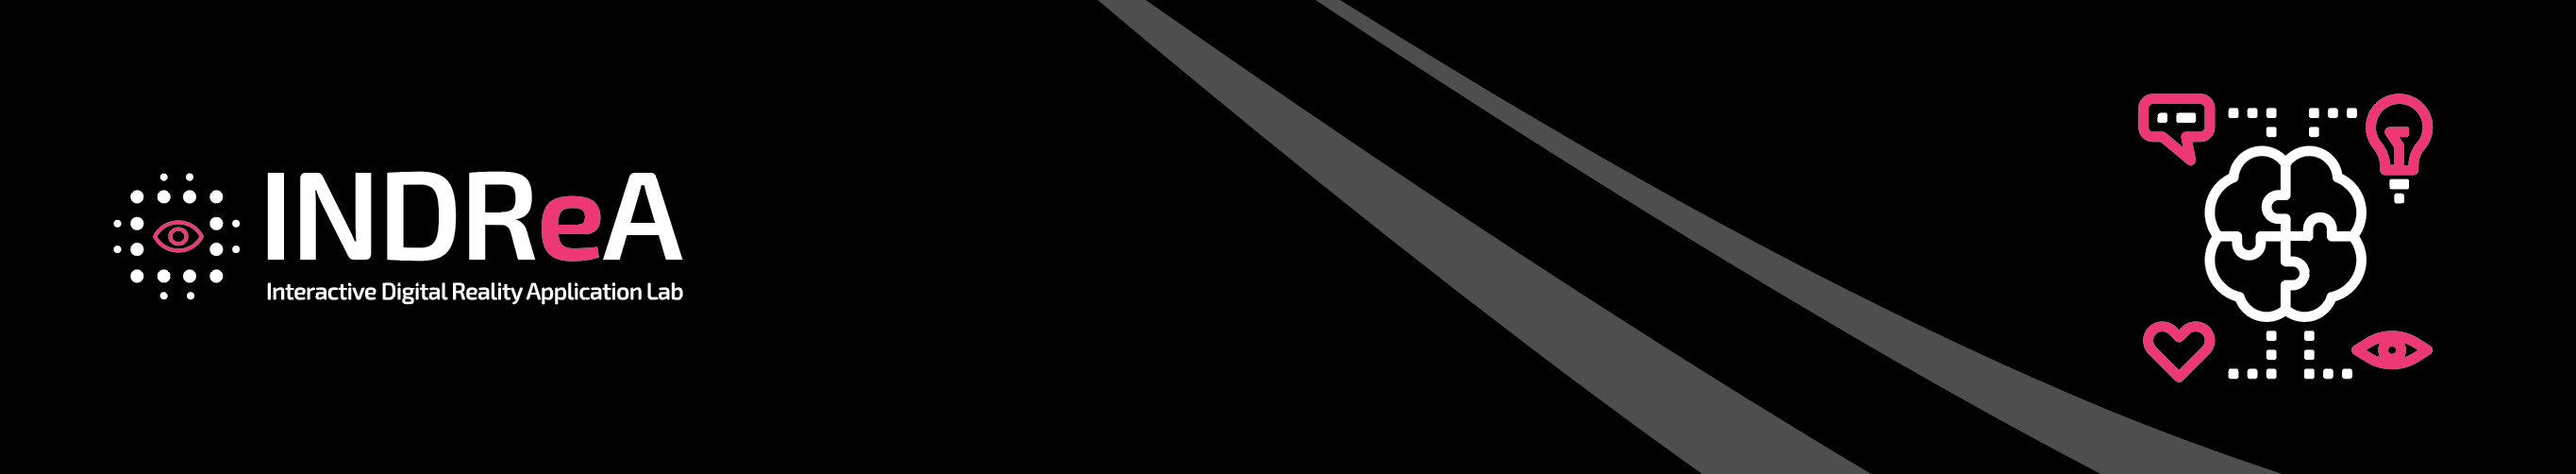

# Signal Processing Pipeline for cleaning EEG signals

INDReA Lab, Department of Design, IIT Hyderabad

V 2.1

### Naming convention of signal variables in the code
'n' is number of eeg channels present in the raw object.
1. raw = Raw EDF data exported from Emotiv Epoch x with 60 channels including non-eeg data
2. raw_n = A subset of raw object. +*+++
3. rawf_n = Bandpass filtered raw data.

### Importing essential libraries

In [1]:
%matplotlib notebook
import matplotlib
import matplotlib.pyplot as plt
plt.ion() 
import numpy as np
import pathlib 
import mne
from mne import Epochs 
from mne.time_frequency import psd_array_multitaper
import mplcursors 
import scipy
from datetime import datetime
import pandas as pd
from matplotlib.widgets import Cursor
from scipy.signal import welch

### Set the backend for interactive plotting

In [2]:
matplotlib.use('TkAgg')

### Set the import and export paths here 

In [3]:
# Raw .edf file to be processed
raw_path='P2_T1.edf'

In [4]:
output_directory_name = 'ICA Completed files'
trial_name = 'P7_T3_'
extension_name = '.fif'

#Define a export function 
def save_file (raw,file_name):
    saved_name = output_directory_name+trial_name+file_name+extension_name
    raw.save(saved_name, overwrite=True)

### Importing the raw data for processing

Extracting EDF parameters from C:\Users\Suyash\Documents\Python\P2_T1.edf...
EDF file detected
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 55039  =      0.000 ...   214.996 secs...
<Info | 8 non-empty values
 bads: []
 ch_names: AF3, F7, F3, FC5, FC6, F4, F8, AF4
 chs: 8 EEG
 custom_ref_applied: False
 highpass: 0.0 Hz
 lowpass: 128.0 Hz
 meas_date: 2023-11-02 18:37:50 UTC
 nchan: 8
 projs: []
 sfreq: 256.0 Hz
 subject_info: <subject_info | his_id: >
>
Using matplotlib as 2D backend.


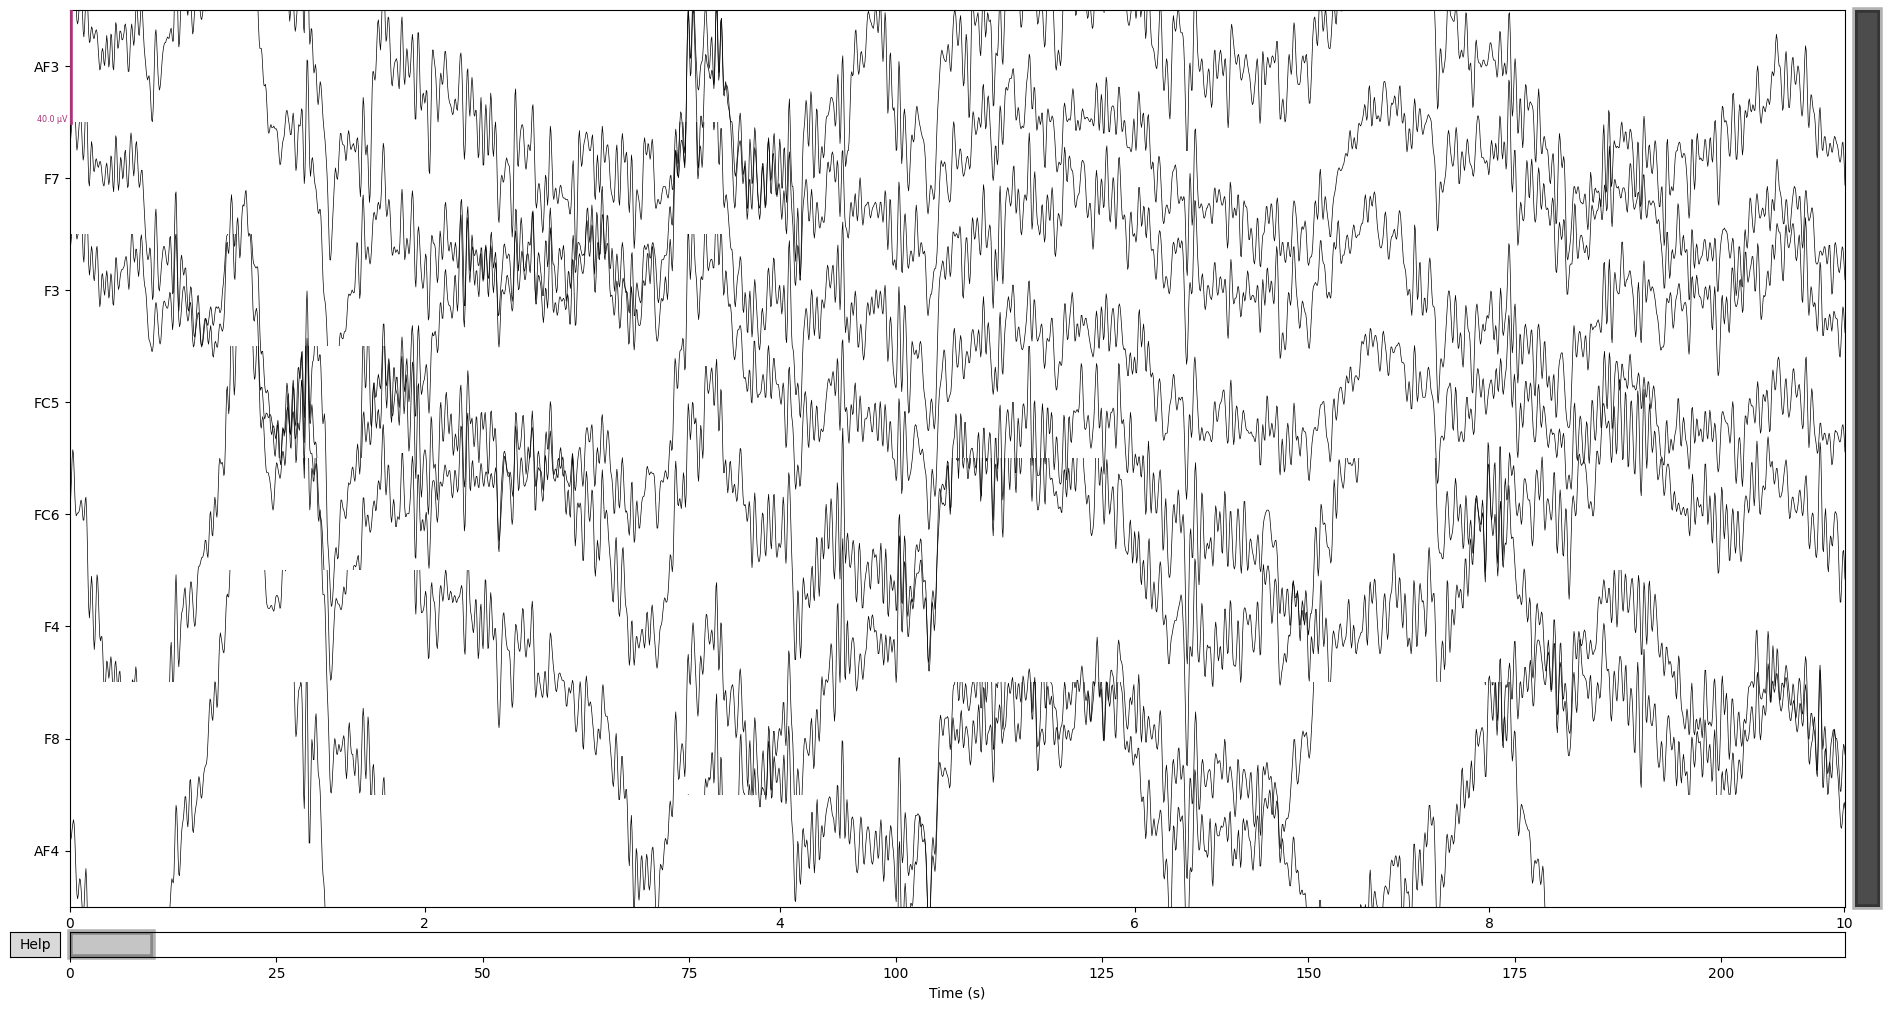

In [5]:
raw = mne.io.read_raw_edf(raw_path, preload=True)

# Making copy of the raw file 
raw_8 = raw.copy()

# Define the channel names
channels_8 = ['AF3','F7','F3','FC5','FC6','F4','F8','AF4']

#Create new raw objects from the subset selections for further analysis
raw_8.pick(channels_8) 

print(raw_8.info)

raw_8.plot()

In [6]:
# Get the measurement start time
meas_date = raw_8.info['meas_date']
    
# Handle different types of meas_date
if isinstance(meas_date, tuple):
    meas_date_timestamp = meas_date[0].timestamp()
elif isinstance(meas_date, datetime):
    meas_date_timestamp = meas_date.timestamp()
else:
    raise ValueError("meas_date is not in a recognized format.")

#Time Correction factor for Emotive device GMT to IST offset of 5 hrs 30 mins
time_correction = 19800
eeg_start_unix = meas_date_timestamp - time_correction

#Calculate duration of the signal 
sfreq = raw_8.info['sfreq']
signal_duration_secs = len(raw_8.times) / sfreq

eeg_end_unix = eeg_start_unix + signal_duration_secs

print(f' Date and time of recording in GMT : {meas_date}')
print(f' GMT UNIX value : {meas_date_timestamp}')
print(f' Actual EEG start time in UNIX : {eeg_start_unix}')
print(f' Actual EEG end time in UNIX : {eeg_end_unix}')
print(f' Total duration of signal : {signal_duration_secs} sec')

 Date and time of recording in GMT : 2023-11-02 18:37:50+00:00
 GMT UNIX value : 1698950270.0
 Actual EEG start time in UNIX : 1698930470.0
 Actual EEG end time in UNIX : 1698930685.0
 Total duration of signal : 215.0 sec


### Mark bad channels if any

In [7]:
# List the channels you want to mark as bad
bad_channels = ['FC5']

# Add the bad channels to the info['bads'] list
raw_8.info['bads'].extend(bad_channels)
print("Bad channels before interpolation:", raw_8.info['bads'])



Bad channels before interpolation: ['FC5']


### Custom montage 

In [8]:
emotiv_montage = mne.channels.make_standard_montage("standard_1020")

#To create the custom montage, we need the actual locations X,Y,Z of the 10-20 system.
emotiv_montage.get_positions()

# Dictionary mapping channel names to (x, y, z) coordinates

positions_8 = { 
    'AF3': (-0.0337007,  0.0768371,  0.021227),
    'F7': (-0.0702629,  0.0424743, -0.01142),
    'F3': (-0.0502438,  0.0531112,  0.042192),
    'FC5': (-0.0772149,  0.0186433,  0.02446),
    'FC6': (0.0795341, 0.0199357, 0.024438),
    'F4': (0.0518362, 0.0543048, 0.040814 ),
    'F8': (0.0730431,  0.0444217, -0.012),
    'AF4': (0.0357123, 0.0777259, 0.021956),
}


# Create a customised DigMontage object
emotiv_montage_8 = mne.channels.make_dig_montage(ch_pos= positions_8, coord_frame='head')

# Set the montage to the raw object to obtain digitaization points
raw_8.set_montage(emotiv_montage_8)

# Plot the sensor locations with the updated montage. Dig. points are needed to plot the scalp topomaps
#raw_14.plot_sensors(show_names=True)

<RawEDF | P2_T1.edf, 8 x 55040 (215.0 s), ~3.4 MiB, data loaded>

In [9]:
# Load a standard EEG electrode layout
montage = mne.channels.make_standard_montage('standard_1020')

# Apply it to your EEG data
raw_8.set_montage(montage)

# Now interpolate bad channels
raw_8.interpolate_bads(reset_bads=True)


Setting channel interpolation method to {'eeg': 'spline'}.
Interpolating bad channels.
    Automatic origin fit: head of radius 82.9 mm
Computing interpolation matrix from 7 sensor positions
Interpolating 1 sensors


C:\Users\Suyash\AppData\Local\Temp\ipykernel_9400\1835001025.py:8: RuntimeWarning: Only 8 head digitization points of the specified kinds ("eeg", "extra",), fitting may be inaccurate
  raw_8.interpolate_bads(reset_bads=True)
C:\Users\Suyash\AppData\Local\Temp\ipykernel_9400\1835001025.py:8: RuntimeWarning: (X, Y) fit (-0.2, 35.5) more than 20 mm from head frame origin
  raw_8.interpolate_bads(reset_bads=True)


<RawEDF | P2_T1.edf, 8 x 55040 (215.0 s), ~3.4 MiB, data loaded>

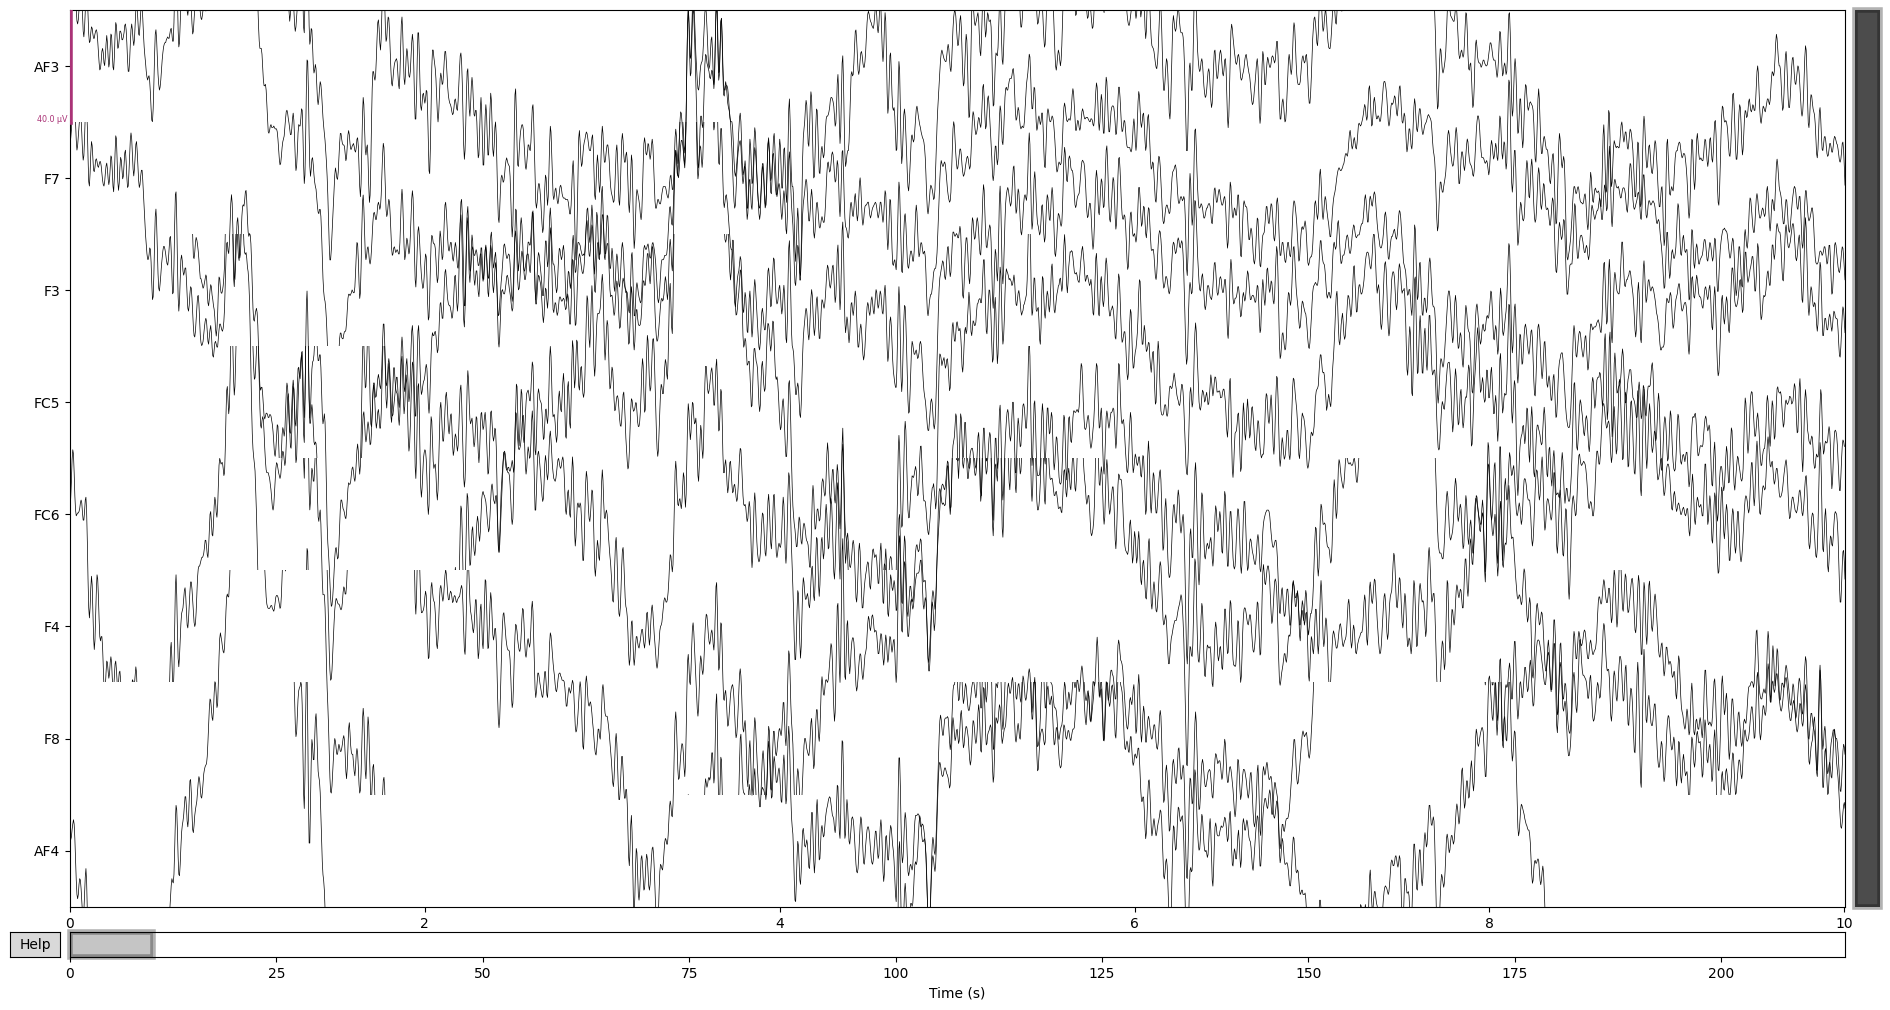

In [10]:
raw_8.plot()

In [11]:
#Save the file
push_to_csv (raw_8, 'trial')

NameError: name 'push_to_csv' is not defined

### Calculating signal length

In [ ]:
#Calculate the total length of the signal in seconds
sfreq = raw_8.info['sfreq']
signal_duration_secs = len(raw_8.times) / sfreq
print(f" Length of raw signal = {signal_duration_secs} sec")

## _**Artefact Removal Process**_ 

### Step 1 : Band pass filtering {1 Hz - 40 Hz} and annotating bad signal portions

In [ ]:
rawf_8 = raw_8.copy()

# Apply high-pass filter to remove slow drifts (e.g., cut-off at 1 Hz)
rawf_8.filter(l_freq=1, h_freq=None, fir_design='firwin')

# Apply low-pass filter to remove high-frequency noise (e.g., cut-off at 40 Hz)
rawf_8.filter(l_freq=None, h_freq=40., fir_design='firwin')


In [ ]:
rawf_8.plot()

In [ ]:
push_to_csv(rawf_8,'filtered')

In [ ]:
#Export the filtered signal
save_file(rawf_8,'rawf_1_50')

### Step 2 : Independent Component Analysis (ICA) | Threshold = 200 uV

In [ ]:
from mne.preprocessing import ICA

# Create an ICA object
ica_8 = ICA(n_components=8, random_state=97, max_iter=15000)

# Additional amplitude-based criteria
reject_criteria = dict(eeg=200e-6)  

# Fit the ICA model to raw the data
ica_8.fit(rawf_8, reject=reject_criteria, flat=None, reject_by_annotation=True)


#### ICA | Plots

In [ ]:
### ------------Plot cascaded time series of individual ICA components-------------###
ica_8.plot_sources(rawf_8)

In [ ]:
### ------------Plot scalp topomaps of the ICA components-------------###
timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
ica_8.plot_components()

In [ ]:
### ------------Plotting individual ICA components Spectral Density -------------###

# Define frequency range
frequencies = np.logspace(0, 2, 100)

# Get a colormap
cmap = plt.get_cmap('plasma')

# Create a figure and axis
fig, ax = plt.subplots()

# Plot PSD of individual ICA components with distinct colors
for idx in range(ica_8.n_components_):
    color = cmap(idx / ica_8.n_components_)  # Use the colormap to get a distinct color
    psd, freqs = plt.psd(ica_8.get_sources(rawf_8).get_data()[idx], NFFT=1024, Fs=rawf_8.info['sfreq'], noverlap=512, label=f'Component {idx}', color=color)

# Add legend
plt.legend()

# Set plot labels
plt.title('Power Spectral Density of ICA Components')
plt.xlabel('Frequency (Hz)')
plt.ylabel('Power/Frequency (dB/Hz)')

# Zoom out after all components have been plotted
plt.autoscale()

# Enable hover tooltips
cursor = mplcursors.cursor(hover=True)

# Define the hover tooltip format
@cursor.connect("add")
def on_hover(sel):
    idx = int(sel.artist.get_label().split()[-1])  # Extract the component index from the label
    sel.annotation.set_text(f'Component {idx}')

# Display the plot
plt.show()

#### ICA | Muscle artefact identification

In [ ]:
muscle_idx_auto, scores = ica_8.find_bads_muscle(rawf_8)
print(muscle_idx_auto)

#### ICA | Exclude and apply to rawfa signal

In [ ]:
# Exclude marked bad components
ica_8.exclude = [1,2,4,6,7]  # Replace with the indices of the components you want to exclude
ica_8.apply(rawf_8)
rawf_8.plot(title = 'rawf_8 after applying ICA')


In [ ]:
save_file(rawf_8, 'ICA_done')